In [116]:
from itertools import cycle, pairwise

import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

# Albert-Laszlo Barabasi - Network Science - Chapter 2 

## Exercises
---

## 2.1 Which of the icons in Figure 2.19 can be drawn without raising your pencil from the paper, and without drawing any line more than once? Why?

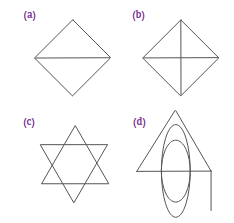

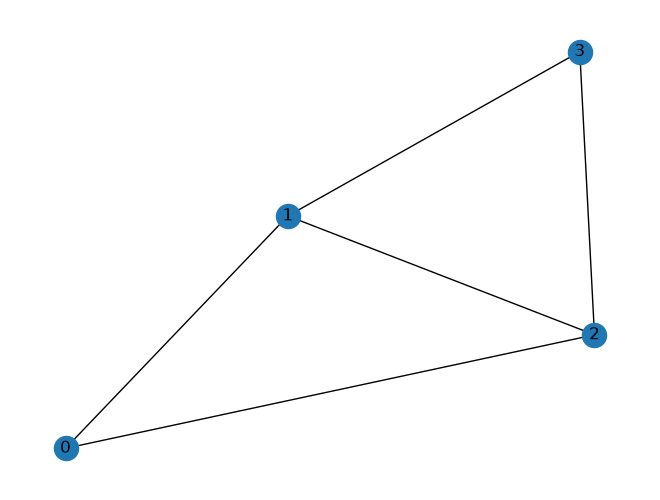

In [117]:
network_a = nx.Graph()
network_a.add_edges_from([(0, 1), (0, 2), (1, 2), (3, 1), (3, 2)])
nx.draw(network_a, with_labels=True)
plt.show()

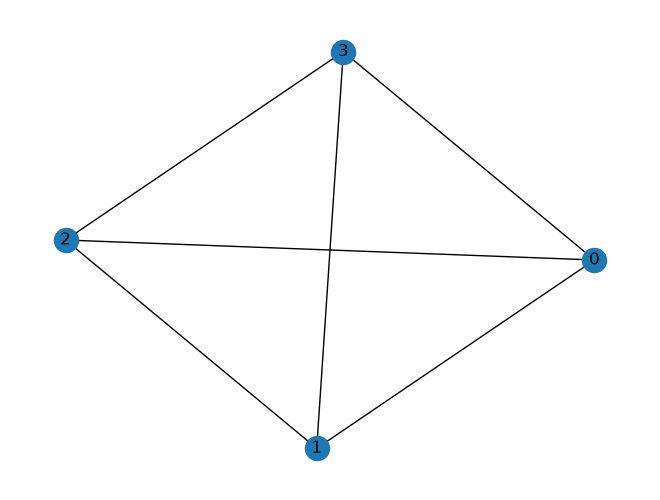

In [118]:
network_b = nx.complete_graph(n=4)
nx.draw(network_b, with_labels=True)
plt.show()

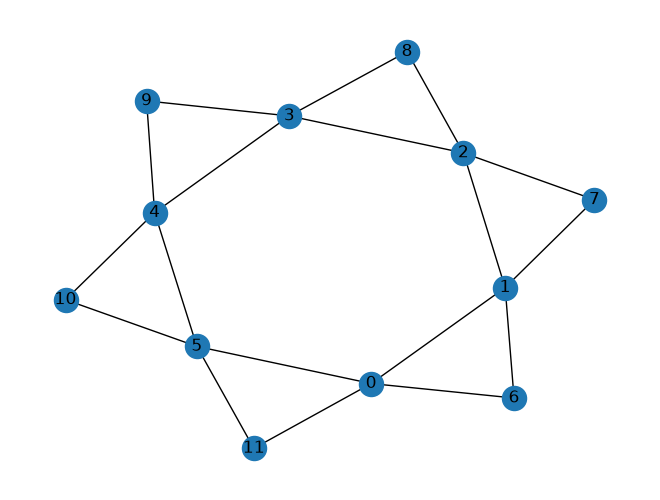

In [119]:
network_c = nx.cycle_graph(n=6)
network_c.add_edges_from(
    [
        edge
        for (i, j), k in zip(pairwise(cycle(list(range(6)))), range(6, 12))
        for edge in [(i, k), (k, j)]
    ]
)
nx.draw(network_c, with_labels=True)
plt.show()

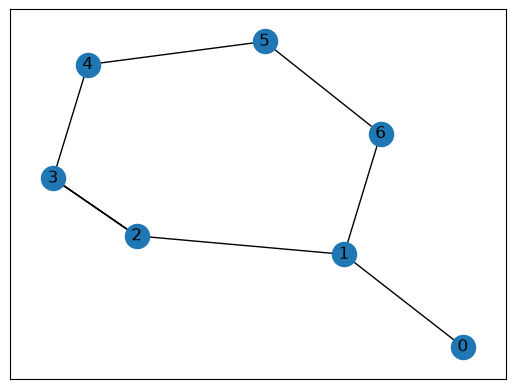

[(0, 1, 0), (1, 2, 0), (1, 6, 0), (2, 3, 0), (2, 3, 1), (2, 3, 2), (3, 4, 0), (4, 5, 0), (5, 6, 0)]


In [120]:
network_d = nx.MultiGraph()
circuit = nx.MultiGraph(nx.cycle_graph([i for i in range(1, 7)]))
network_d.add_edges_from([(0, 1), (2, 3), (2, 3),(2, 3)])
network_d = nx.compose(network_d, circuit)
pos = nx.spring_layout(network_d)
nx.draw_networkx_nodes(network_d, pos)
nx.draw_networkx_labels(network_d, pos)


nx.draw_networkx_edges(
    network_d, pos,  
)

plt.show()
print(network_d.edges)

In [121]:
print(network_a.degree)
print(network_b.degree)
print(network_c.degree)
print(network_d.degree)

[(0, 2), (1, 3), (2, 3), (3, 2)]
[(0, 3), (1, 3), (2, 3), (3, 3)]
[(0, 4), (1, 4), (2, 4), (3, 4), (4, 4), (5, 4), (6, 2), (7, 2), (8, 2), (9, 2), (10, 2), (11, 2)]
[(0, 1), (1, 3), (2, 4), (3, 4), (4, 2), (5, 2), (6, 2)]


Existe uma maneira de percorrer os verticies das figuras `a)` , `c)` e `d)`. Existe um caminho euleriano quando o grafo é conectado e o número de vértices com grau impar é $2k$, para $k=0$ ou $k=1$, com todos os outros vértices com grau par. O grafo `c)` é um grafo completo com todos os vértices com grau 3.

---

## 2.2. Matrix Formalism

Let A be the N x N adjacency matrix of an undirected unweighted network, without self-loops. Let 1 be a column vector of N elements, all equal to 1. In other words 1 = (1, 1, ..., 1)T , where the superscript T indicates the transpose operation. Use the matrix formalism (multiplicative constants, multiplication row by column, matrix operations like transpose and trace, etc, but avoid the sum symbol ∑) to write expressions for:

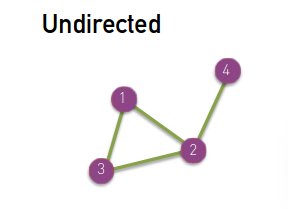

`a)` The vector $k$ whose elements are the degrees $k_i$ of all nodes  $i = 1, 2,\dots, N$.

In [122]:
A = np.array([[0,1,1,0], [1,0,1,1], [1,1,0,0], [0,1,0,0]])
A.shape

(4, 4)

In [123]:
ones_vector = np.ones(shape=(A.shape[0], 1))
ones_vector

array([[1.],
       [1.],
       [1.],
       [1.]])

In [124]:
k = A @ ones_vector
k

array([[2.],
       [3.],
       [2.],
       [1.]])

`b)` The total number of links, $L$, in the network.

The number of links in a graph is defined by the expression $\frac{1}{2} \sum^{N}_{i,j=1}= A_{ij}$. 


This expression can be rewritten in matrix form as $\frac{1}{2}(1^T A 1)$

In [125]:
L = 1/2 *(ones_vector.T @ A @ ones_vector)
L

array([[4.]])

`c)` The number of triangles $T$ present in the network, where a triangle means three nodes, each connected by links to the other two (Hint: you can use the trace of a matrix).

For this, we need to use the power operation of a Matrix. That is $A^n = A \times A \times \dots \times A$, the matrix $A$ multiplied by itself $n$ times 

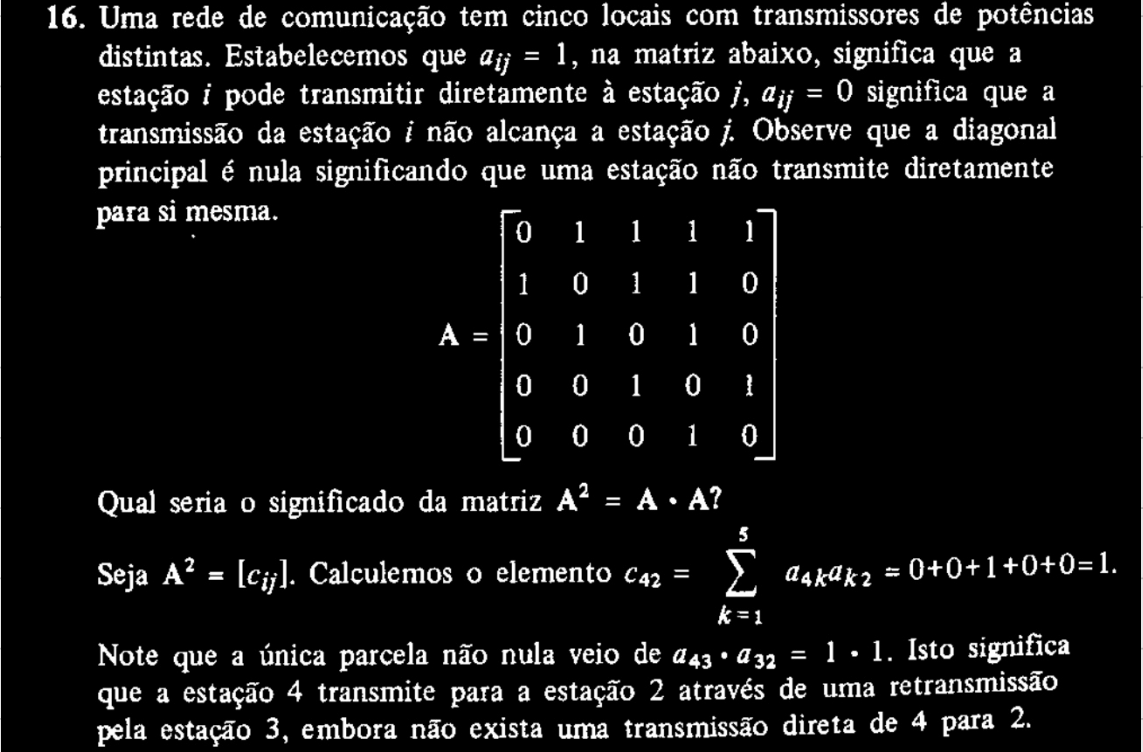

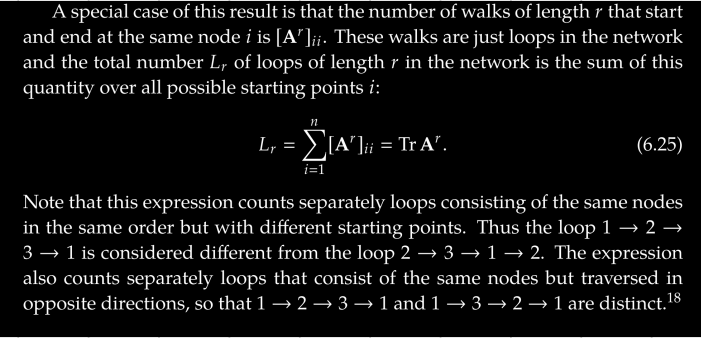

The triangles are the loops of size 3. So in this case we can use $r=3$

In [126]:
T = np.trace(np.linalg.matrix_power(A, 3))
T

np.int64(6)

`d)` The vector $k_{nn}$ whose element $i$ is the sum of the degrees of node  $i$'s neighbors.

$A^2$ gives the number of walks of length 2 from every node

In [127]:
knn = np.linalg.matrix_power(A,2) @ ones_vector
knn

array([[5.],
       [5.],
       [5.],
       [3.]])

`e)` The vector $k_{nnn}$ whose element $i$ is the sum of the degrees of node  $i$'s second neighbors.

Sorry, this one I couldn't figure it out yet. Need help...

---

## 2.3. Graph Representation

The adjacency matrix is a useful graph representation for many analytical calculations. However, when we need to store a network in a computer, we can save computer memory by offering the list of links in a $L\times2$ matrix, whose rows contain the starting and end point $i$ and $j$ of each link.

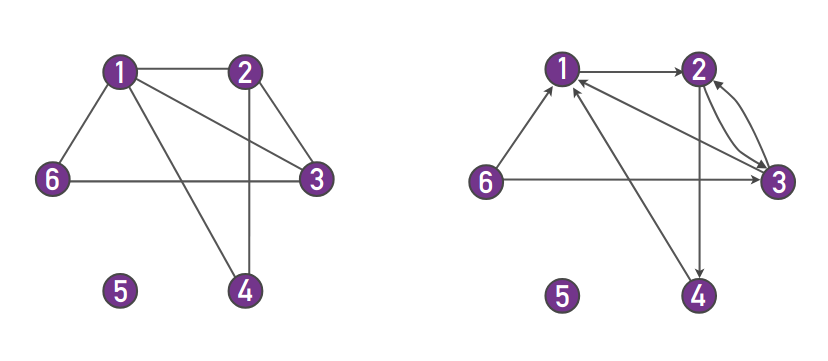

`a)` The corresponding adjacency matrices.

In [128]:
undirected_graph_A = np.array([[0,1,1,1,0,1], [1,0,1,1,0,0] ,[1,1,0,0,0,1],[1,1,0,0,0,0],[0,0,0,0,0,0],[1,0,1,0,0,0]])
directed_graph_A = np.array([[0,1,0,0,0,0], [0,0,1,1,0,0] ,[1,1,0,0,0,0],[1,0,0,0,0,0],[0,0,0,0,0,0],[1,0,1,0,0,0]])


`b)` The corresponding link lists.

In [129]:
undirected_graph_List = [(1,2), (1,3), (1,4), (1,6),(2,3),(2,4), (3,6)]
directed_graph_List =   [(1,2), (2,3), (2,4), (3,1),(3,2),(4,1), (6,1), (6,3)]

`c)` Determine the average clustering coefficient of the network shown in Figure 2.20a.

In [130]:
undirected_graph = nx.from_numpy_array(A=undirected_graph_A)
print(nx.clustering(undirected_graph))
print(nx.average_clustering(undirected_graph))

{0: 0.5, 1: 0.6666666666666666, 2: 0.6666666666666666, 3: 1.0, 4: 0, 5: 1.0}
0.6388888888888888


In [131]:
directed_graph = nx.DiGraph(nx.from_numpy_array(A=directed_graph_A))
print(nx.clustering(directed_graph))
print(nx.average_clustering(directed_graph))

{0: 0.5, 1: 0.6666666666666666, 2: 0.6666666666666666, 3: 1.0, 4: 0, 5: 1.0}
0.6388888888888888


`d)` If you switch the labels of nodes 5 and 6 in Figure 2.20a, how does  that move change the adjacency matrix? And the link list?

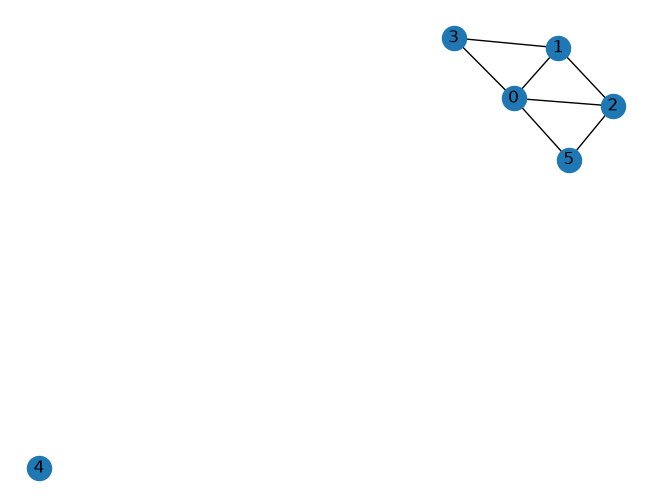

In [132]:
nx.draw(undirected_graph, with_labels=True)
plt.show()

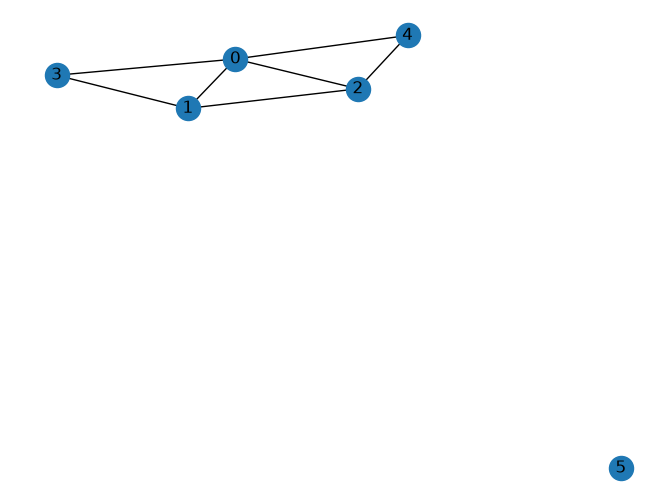

In [133]:
changed_undirected_graph_A = np.array([[0,1,1,1,1,0], [1,0,1,1,0,0] ,[1,1,0,0,1,0],[1,1,0,0,0,0],[1,0,1,0,0,0],[0,0,0,0,0,0]])
changed_undirected_graph = nx.from_numpy_array(A=changed_undirected_graph_A)
nx.draw(changed_undirected_graph, with_labels=True)
plt.show()

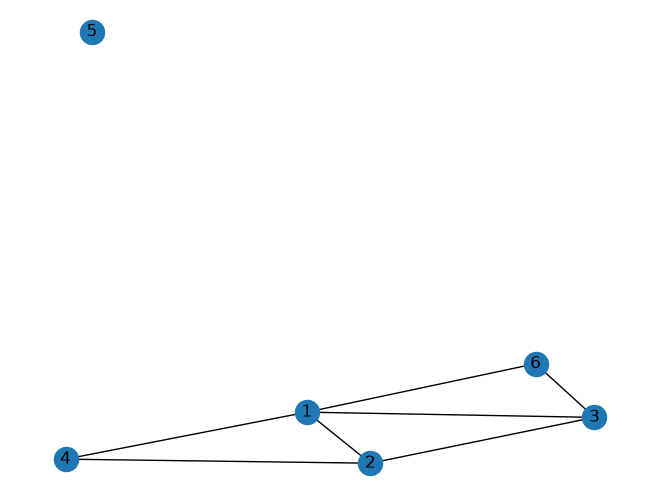

In [134]:
undirected_from_list = nx.Graph([(1,2), (1,3), (1,4), (1,6),(2,3),(2,4), (3,6)])
undirected_from_list.add_node(5)
nx.draw(undirected_from_list, with_labels=True)
plt.show()

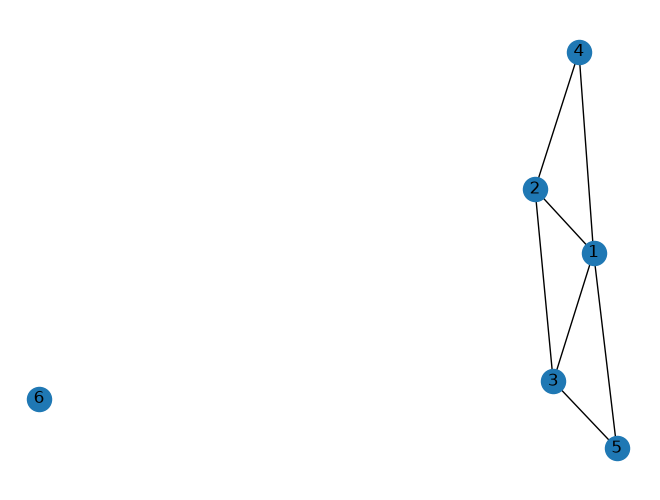

In [135]:
undirected_from_list = nx.Graph([(1,2), (1,3), (1,4), (1,5),(2,3),(2,4), (3,5)])
undirected_from_list.add_node(6)
nx.draw(undirected_from_list, with_labels=True)
plt.show()

`e)` What kind of information can you not infer from the link list  representation of the network that you can infer from the adjacency matrix?

The list only tells the labels for which there are links between nodes. So there could be multiple nodes without links on the network, and only the adjacency matrix will tell.

---

## 2.6. Bipartite Networks - General Considerations

`a)` What is the maximum number of links $L_{max}$ the network can  have?

Each of the nodes of the $N_1$ nodes has $N_2$ links to the other $N_2$ nodes. So there are at most $N_1 \times N_2$ links.

`b)` How many links cannot occur compared to a non-bipartite network of size $N = N_1 + N_2$ ?

The following states a inequality that demonstrates how many links are not possible to happen in a bipartite network:

Let $N_1 \times N_2$ be the max number of links in a bipartite network
The number of links $L$ of a unidirected network with $N_1 + N_2$ nodes with the maximum number of links (including self loops) can be expressed as follows:
$L = \frac{1}{2}\sum^{N_1 + N_2}_{i,j=1} A_{ij}$, where $A_{ij}=1, \forall i,j$

$$
\begin{align*}
N_1 \times N_2 &\lt \frac{1}{2}\sum^{N_1 + N_2}_{i,j=1} A_{ij} \\
N_1 \times N_2 &\lt \frac{1}{2}\sum^{N_1 + N_2}_{i,j=1} 1 \\
N_1 \times N_2 &\lt \frac{1}{2}(N_1 + N_2)^2 \\
N_1 \times N_2 &\lt \frac{(N_1^2 + 2N_1N_2 + N^2)}{2} \\
\end{align*}
$$

So there cannot be:
$$
\begin{align*}
 \frac{(N_1^2 + 2N_1N_2 + N^2)}{2} - N_1N_2 \\
 \frac{(N_1^2 + 2N_1N_2 + N^2) -2N_1N_2}{2}&= \frac{(N_1^2+ N^2)}{2}\\
\end{align*}
$$
